#                                                                                  UK monetary policy, inflation and FTSE 100 analysis

 This project investigates the empirical relationship in the UK between inflation, bank interest rate changes and FTSE 100 monthly returns from 2005-2026
 This analysis uses macroeconomic data with financial market data within the UK
 Python is used to clean and merge datasets, calculate returns, visuialise trends and estimate regression models

 ## Hypothesis
 H0: UK inflation and bank rate changes have no significant correlation with FTSE 100 monthly returns
 
 H1: UK inflation and bank rate changes have a negative relationship with FTSE 100 monthly returns

### 1. Imports and setup

In [444]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm


### 2. Data collection

In [445]:
start_date = "2005-01-01"
end_date = "2026-10-01"

ftse = yf.Ticker("^FTSE").history(
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=False
)

ftse.head()

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2005-01-04 00:00:00+00:00,4814.299805,4851.600098,4809.399902,4847.000000,4847.000000,1613071800,0.0,0.0
2005-01-05 00:00:00+00:00,4847.000000,4847.000000,4806.000000,4806.000000,4806.000000,1802853600,0.0,0.0
2005-01-06 00:00:00+00:00,4806.000000,4833.299805,4806.000000,4824.299805,4824.299805,1407245400,0.0,0.0
2005-01-07 00:00:00+00:00,4824.299805,4863.500000,4819.799805,4854.100098,4854.100098,1635917100,0.0,0.0
2005-01-10 00:00:00+00:00,4854.100098,4858.899902,4833.399902,4840.700195,4840.700195,1187808600,0.0,0.0


In [446]:
ftse.tail()

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2026-09-24 00:00:00+01:00,10705.500000,10741.099609,10666.900391,10680.000000,10680.000000,971886900,0.0,0.0
2026-09-25 00:00:00+01:00,10679.900391,10753.400391,10667.000000,10695.299805,10695.299805,701463900,0.0,0.0
2026-09-28 00:00:00+01:00,10695.200195,10758.700195,10684.900391,10684.900391,10684.900391,536195200,0.0,0.0
2026-09-29 00:00:00+01:00,10685.200195,10756.200195,10622.000000,10636.700195,10636.700195,741634900,0.0,0.0
2026-09-30 00:00:00+01:00,10635.799805,10725.299805,10599.200195,10606.000000,10606.000000,964213900,0.0,0.0


In [447]:
ftse.shape


(5492, 8)

In [448]:
ftse = ftse[["Close"]].copy()
ftse.head()

,Close
Date,
2005-01-04 00:00:00+00:00,4847.000000
2005-01-05 00:00:00+00:00,4806.000000
2005-01-06 00:00:00+00:00,4824.299805
2005-01-07 00:00:00+00:00,4854.100098
2005-01-10 00:00:00+00:00,4840.700195


In [449]:
ftse.to_csv("data/ftse100_daily.csv")

In [450]:
import os
print(os.getcwd())

c:\Users\Josh\Documents\FTSE monetary policy


In [451]:
print(os.listdir("data"))
print(os.listdir("data/raw"))


['ftse100_daily.csv', 'Processed', 'Raw']
['boe_bank_rate_daily.csv', 'ftse100_daily.csv', 'ons_cpi_d7g7.csv']


In [452]:
cpi = pd.read_csv("data/raw/ons_cpi_d7g7.csv")
cpi.head()

,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100
0,CDID,D7G7
1,Source dataset ID,MM23
2,PreUnit,NaN
3,Unit,%
4,Release date,16-09-2026


In [453]:
bank_rate = pd.read_csv("data/raw/boe_bank_rate_daily.csv")
bank_rate.head()

,Date Changed,Rate
0,18 Dec 25,3.75
1,07 Aug 25,4.00
2,08 May 25,4.25
3,06 Feb 25,4.50
4,07 Nov 24,4.75


In [454]:
cpi.shape
bank_rate.shape

(258, 2)

In [455]:
cpi.columns
bank_rate.columns

Index(['Date Changed', 'Rate'], dtype='str')

In [456]:
cpi.head(20)

,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100
0,CDID,D7G7
1,Source dataset ID,MM23
2,PreUnit,NaN
3,Unit,%
4,Release date,16-09-2026
5,Next release,21 October 2026
6,Important notes,NaN
7,1989,5.2
8,1990,7.0
9,1991,7.5


In [457]:
cpi.tail(20)


,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100
626,2025 JAN,3.0
627,2025 FEB,2.8
628,2025 MAR,2.6
629,2025 APR,3.5
630,2025 MAY,3.4
631,2025 JUN,3.6
632,2025 JUL,3.8
633,2025 AUG,3.8
634,2025 SEP,3.8
635,2025 OCT,3.6


### 3. Data cleaning

In [458]:
cpi.info()

<class 'pandas.DataFrame'>
RangeIndex: 646 entries, 0 to 645
Data columns (total 2 columns):
 #   Column                                  Non-Null Count  Dtype
---  ------                                  --------------  -----
 0   Title                                   646 non-null    str  
 1   CPI ANNUAL RATE 00: ALL ITEMS 2015=100  644 non-null    str  
dtypes: str(2)
memory usage: 10.2 KB


In [459]:
print(cpi.columns)

Index(['Title', 'CPI ANNUAL RATE 00: ALL ITEMS 2015=100'], dtype='str')


In [460]:
monthly_cpi = cpi[
    cpi["Title"].str.match(r"^\d{4} [A-Z]{3}$", na=False)
].copy()

monthly_cpi.head()

,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100
194,1989 JAN,4.9
195,1989 FEB,5.0
196,1989 MAR,5.0
197,1989 APR,5.3
198,1989 MAY,5.3


In [461]:
monthly_cpi.columns = ["Date", "CPI_Inflation"]

monthly_cpi.head()

,Date,CPI_Inflation
194,1989 JAN,4.9
195,1989 FEB,5.0
196,1989 MAR,5.0
197,1989 APR,5.3
198,1989 MAY,5.3


In [462]:
monthly_cpi["Date"] = pd.to_datetime(
    monthly_cpi["Date"],
    format="%Y %b"
)

monthly_cpi.head()

,Date,CPI_Inflation
194,1989-01-01,4.9
195,1989-02-01,5.0
196,1989-03-01,5.0
197,1989-04-01,5.3
198,1989-05-01,5.3


In [463]:
monthly_cpi["CPI_Inflation"] = pd.to_numeric(
    monthly_cpi["CPI_Inflation"]
)

In [464]:
monthly_cpi = monthly_cpi[
    monthly_cpi["Date"] >= "2005-01-01"
].copy()

In [465]:
print(monthly_cpi.head())
print(monthly_cpi.tail())
print(monthly_cpi.shape)
print(monthly_cpi.dtypes)

          Date  CPI_Inflation
386 2005-01-01            1.6
387 2005-02-01            1.7
388 2005-03-01            1.9
389 2005-04-01            1.9
390 2005-05-01            1.9
          Date  CPI_Inflation
641 2026-04-01            2.8
642 2026-05-01            2.8
643 2026-06-01            2.6
644 2026-07-01            2.9
645 2026-08-01            3.1
(260, 2)
Date             datetime64[us]
CPI_Inflation           float64
dtype: object


In [466]:
monthly_cpi.to_csv("data/processed/cpi_monthly.csv", index=False)

In [467]:
bank_rate["Date Changed"] = pd.to_datetime(
    bank_rate["Date Changed"],
    format="%d %b %y"
)

bank_rate["Rate"] = pd.to_numeric(bank_rate["Rate"])

bank_rate.head()

,Date Changed,Rate
0,2025-12-18,3.75
1,2025-08-07,4.00
2,2025-05-08,4.25
3,2025-02-06,4.50
4,2024-11-07,4.75


In [468]:
bank_rate = bank_rate.sort_values("Date Changed")

bank_rate.head()

,Date Changed,Rate
257,1975-01-20,11.25
256,1975-01-27,11.00
255,1975-02-10,10.75
254,1975-02-17,10.50
253,1975-03-10,10.25


In [469]:
bank_rate = pd.read_csv("data/raw/boe_bank_rate_daily.csv")

bank_rate["Date Changed"] = pd.to_datetime(
    bank_rate["Date Changed"],
    format="%d %b %y"
)

bank_rate["Rate"] = pd.to_numeric(bank_rate["Rate"])

bank_rate = bank_rate.sort_values("Date Changed").reset_index(drop=True)

In [470]:
monthly_dates = pd.DataFrame({
    "Date": pd.date_range(
        start="2005-01-01",
        end="2026-09-01",
        freq="MS"
    )
})

In [471]:
monthly_dates = monthly_dates.sort_values("Date")

bank_rate = bank_rate.sort_values("Date Changed")

In [472]:
monthly_bank_rate = pd.merge_asof(
    monthly_dates,
    bank_rate,
    left_on="Date",
    right_on="Date Changed",
    direction="backward"
)

monthly_bank_rate.head(15)

,Date,Date Changed,Rate
0,2005-01-01,2004-08-05,4.75
1,2005-02-01,2004-08-05,4.75
2,2005-03-01,2004-08-05,4.75
3,2005-04-01,2004-08-05,4.75
4,2005-05-01,2004-08-05,4.75
5,2005-06-01,2004-08-05,4.75
6,2005-07-01,2004-08-05,4.75
7,2005-08-01,2004-08-05,4.75
8,2005-09-01,2005-08-04,4.50
9,2005-10-01,2005-08-04,4.50


In [473]:
ftse = ftse.sort_index()

ftse_monthly = ftse.resample("ME").last()

ftse_monthly.head()

,Close
Date,
2005-01-31 00:00:00+00:00,4852.299805
2005-02-28 00:00:00+00:00,4968.500000
2005-03-31 00:00:00+01:00,4894.399902
2005-04-30 00:00:00+01:00,4801.700195
2005-05-31 00:00:00+01:00,4964.000000


In [474]:
ftse_monthly["FTSE_Return"] = ftse_monthly["Close"].pct_change() * 100

ftse_monthly.head()

,Close,FTSE_Return
Date,,
2005-01-31 00:00:00+00:00,4852.299805,NaN
2005-02-28 00:00:00+00:00,4968.500000,2.394745
2005-03-31 00:00:00+01:00,4894.399902,-1.491398
2005-04-30 00:00:00+01:00,4801.700195,-1.893995
2005-05-31 00:00:00+01:00,4964.000000,3.380049


In [475]:
ftse_monthly.index = ftse_monthly.index.to_period("M").to_timestamp()

ftse_monthly.head()

C:\Users\Josh\AppData\Local\Temp\ipykernel_1784\2336162273.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  ftse_monthly.index = ftse_monthly.index.to_period("M").to_timestamp()


,Close,FTSE_Return
Date,,
2005-01-01,4852.299805,NaN
2005-02-01,4968.500000,2.394745
2005-03-01,4894.399902,-1.491398
2005-04-01,4801.700195,-1.893995
2005-05-01,4964.000000,3.380049


In [476]:
ftse_monthly = ftse_monthly.reset_index()

ftse_monthly.columns = ["Date", "FTSE_Close", "FTSE_Return"]

In [477]:
print(ftse_monthly.head())
print(ftse_monthly.tail())
print(ftse_monthly.shape)
print(ftse_monthly.dtypes)

        Date   FTSE_Close  FTSE_Return
0 2005-01-01  4852.299805          NaN
1 2005-02-01  4968.500000     2.394745
2 2005-03-01  4894.399902    -1.491398
3 2005-04-01  4801.700195    -1.893995
4 2005-05-01  4964.000000     3.380049
          Date    FTSE_Close  FTSE_Return
256 2026-05-01  10409.299805     0.293868
257 2026-06-01  10497.099609     0.843475
258 2026-07-01  10868.099609     3.534310
259 2026-08-01  10824.299805    -0.403013
260 2026-09-01  10606.000000    -2.016757
(261, 3)
Date           datetime64[us]
FTSE_Close            float64
FTSE_Return           float64
dtype: object


In [478]:
ftse_monthly.to_csv(
    "data/processed/ftse_monthly.csv",
    index=False
)

In [479]:
monthly_cpi.head()
monthly_bank_rate.head()
ftse_monthly.head()

,Date,FTSE_Close,FTSE_Return
0,2005-01-01,4852.299805,NaN
1,2005-02-01,4968.500000,2.394745
2,2005-03-01,4894.399902,-1.491398
3,2005-04-01,4801.700195,-1.893995
4,2005-05-01,4964.000000,3.380049


In [480]:
monthly_bank_rate = monthly_bank_rate[["Date", "Rate"]].copy()
monthly_bank_rate.columns = ["Date", "Bank_Rate"]

In [481]:
master = pd.merge(
    monthly_cpi,
    monthly_bank_rate,
    on="Date",
    how="inner"
)

In [482]:
master.head()

,Date,CPI_Inflation,Bank_Rate
0,2005-01-01,1.6,4.75
1,2005-02-01,1.7,4.75
2,2005-03-01,1.9,4.75
3,2005-04-01,1.9,4.75
4,2005-05-01,1.9,4.75


In [483]:
print(master.tail())
print(master.shape)
print(master.dtypes)

          Date  CPI_Inflation  Bank_Rate
255 2026-04-01            2.8       3.75
256 2026-05-01            2.8       3.75
257 2026-06-01            2.6       3.75
258 2026-07-01            2.9       3.75
259 2026-08-01            3.1       3.75
(260, 3)
Date             datetime64[us]
CPI_Inflation           float64
Bank_Rate               float64
dtype: object


In [484]:
master.isna().sum()

Date             0
CPI_Inflation    0
Bank_Rate        0
dtype: int64

In [485]:
master = pd.merge(
    master,
    ftse_monthly,
    on="Date",
    how="inner"
)

In [486]:
print(master.columns)

Index(['Date', 'CPI_Inflation', 'Bank_Rate', 'FTSE_Close', 'FTSE_Return'], dtype='str')


In [487]:
master.isna().sum()

Date             0
CPI_Inflation    0
Bank_Rate        0
FTSE_Close       0
FTSE_Return      1
dtype: int64

In [488]:
print(ftse_monthly.columns)

Index(['Date', 'FTSE_Close', 'FTSE_Return'], dtype='str')


In [489]:
master.head()

,Date,CPI_Inflation,Bank_Rate,FTSE_Close,FTSE_Return
0,2005-01-01,1.6,4.75,4852.299805,NaN
1,2005-02-01,1.7,4.75,4968.500000,2.394745
2,2005-03-01,1.9,4.75,4894.399902,-1.491398
3,2005-04-01,1.9,4.75,4801.700195,-1.893995
4,2005-05-01,1.9,4.75,4964.000000,3.380049


In [490]:
master.isna().sum()

Date             0
CPI_Inflation    0
Bank_Rate        0
FTSE_Close       0
FTSE_Return      1
dtype: int64

In [491]:
master["Bank_Rate_Change"] = master["Bank_Rate"].diff()

In [492]:
master["FTSE_Volatility_12M"] = (
    master["FTSE_Return"]
    .rolling(window=12)
    .std()
)

In [493]:
master.head(15)

,Date,CPI_Inflation,Bank_Rate,FTSE_Close,FTSE_Return,Bank_Rate_Change,FTSE_Volatility_12M
0,2005-01-01,1.6,4.75,4852.299805,NaN,NaN,NaN
1,2005-02-01,1.7,4.75,4968.500000,2.394745,0.00,NaN
2,2005-03-01,1.9,4.75,4894.399902,-1.491398,0.00,NaN
3,2005-04-01,1.9,4.75,4801.700195,-1.893995,0.00,NaN
4,2005-05-01,1.9,4.75,4964.000000,3.380049,0.00,NaN
5,2005-06-01,2.0,4.75,5113.200195,3.005645,0.00,NaN
6,2005-07-01,2.3,4.75,5282.299805,3.307119,0.00,NaN
7,2005-08-01,2.4,4.75,5296.899902,0.276397,0.00,NaN
8,2005-09-01,2.5,4.50,5477.700195,3.413323,-0.25,NaN
9,2005-10-01,2.3,4.50,5317.299805,-2.928243,0.00,NaN


### 4. Exploratory analysis

In [494]:
master.describe()

,Date,CPI_Inflation,Bank_Rate,FTSE_Close,FTSE_Return,Bank_Rate_Change,FTSE_Volatility_12M
count,260,260.000000,260.000000,260.000000,259.000000,259.000000,248.000000
mean,2015-10-16 14:01:50.769230,2.886538,2.011923,6692.354999,0.379128,-0.003861,3.517652
min,2005-01-01 00:00:00,-0.100000,0.100000,3830.100098,-13.807253,-1.500000,1.485271
25%,2010-05-24 06:00:00,1.800000,0.500000,5865.300049,-1.746826,0.000000,2.558269
50%,2015-10-16 12:00:00,2.500000,0.500000,6603.149902,0.819176,0.000000,3.323595
75%,2021-03-08 18:00:00,3.300000,4.500000,7419.500122,2.779350,0.000000,4.103056
max,2026-08-01 00:00:00,11.100000,5.750000,10910.599609,12.351862,0.750000,7.436810
std,NaN,2.137786,2.061106,1280.135896,3.694872,0.176817,1.227448


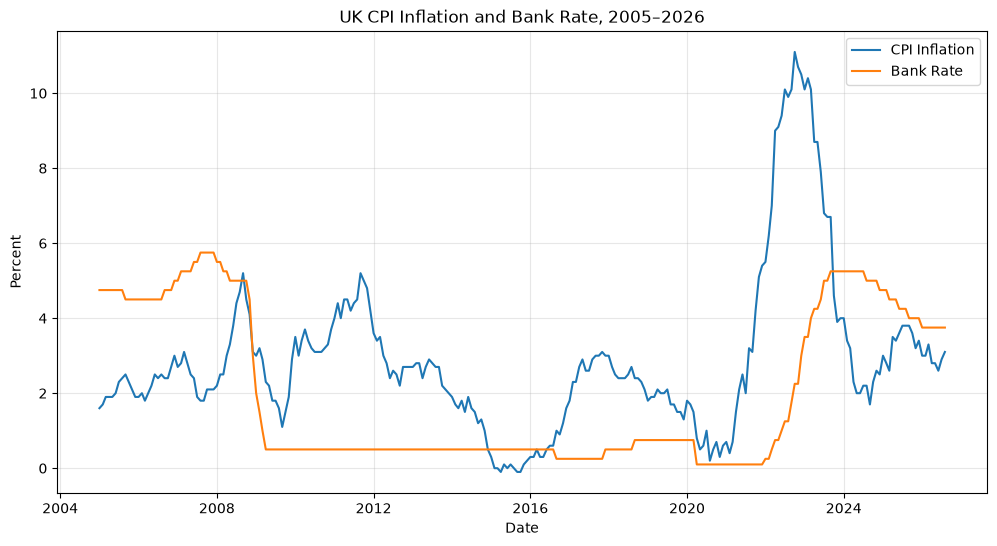

In [495]:
plt.figure(figsize=(12, 6))

plt.plot(master["Date"], master["CPI_Inflation"], label="CPI Inflation")
plt.plot(master["Date"], master["Bank_Rate"], label="Bank Rate")

plt.xlabel("Date")
plt.ylabel("Percent")
plt.title("UK CPI Inflation and Bank Rate, 2005–2026")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "figures/inflation_bank_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

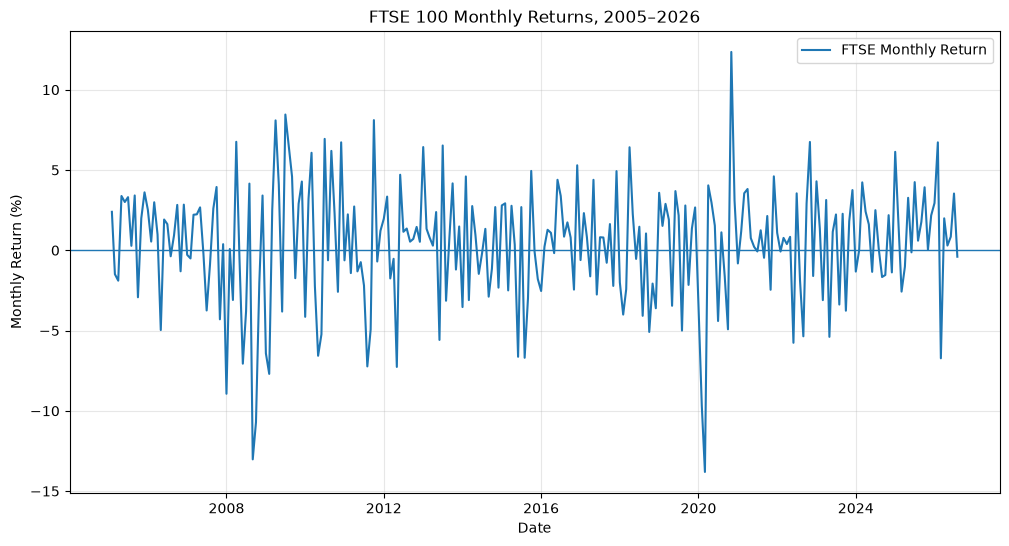

In [496]:
plt.figure(figsize=(12, 6))

plt.plot(master["Date"], master["FTSE_Return"], label="FTSE Monthly Return")

plt.axhline(0, linewidth=1)

plt.xlabel("Date")
plt.ylabel("Monthly Return (%)")
plt.title("FTSE 100 Monthly Returns, 2005–2026")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "figures/ftse_monthly_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

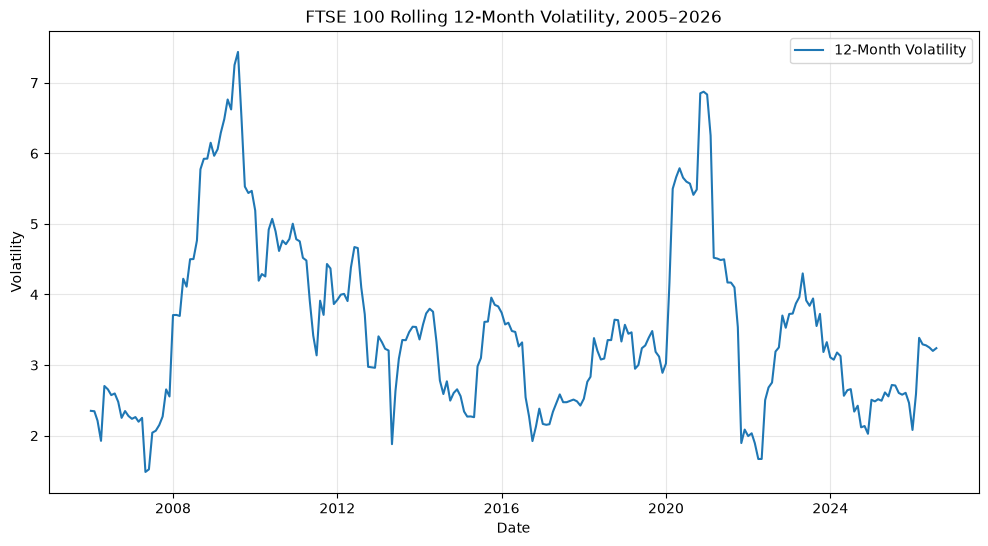

In [497]:
plt.figure(figsize=(12, 6))

plt.plot(master["Date"], master["FTSE_Volatility_12M"], label="12-Month Volatility")

plt.xlabel("Date")
plt.ylabel("Volatility")
plt.title("FTSE 100 Rolling 12-Month Volatility, 2005–2026")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "figures/ftse_rolling_volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5. Correlation analysis

In [498]:
correlations = master[
    ["CPI_Inflation", "Bank_Rate", "Bank_Rate_Change", "FTSE_Return"]
].corr()

correlations

,CPI_Inflation,Bank_Rate,Bank_Rate_Change,FTSE_Return
CPI_Inflation,1.000000,0.193709,0.339210,-0.047620
Bank_Rate,0.193709,1.000000,0.019027,-0.034272
Bank_Rate_Change,0.339210,0.019027,1.000000,0.018715
FTSE_Return,-0.047620,-0.034272,0.018715,1.000000


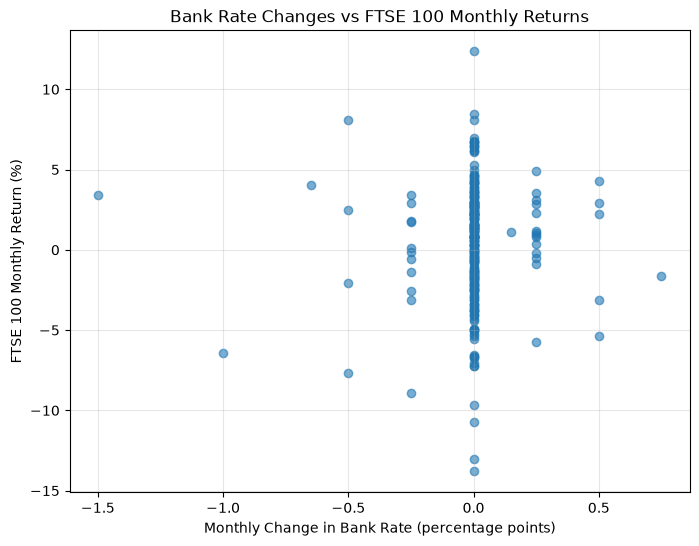

In [499]:
plt.figure(figsize=(8, 6))

plt.scatter(
    master["Bank_Rate_Change"],
    master["FTSE_Return"],
    alpha=0.6
)

plt.xlabel("Monthly Change in Bank Rate (percentage points)")
plt.ylabel("FTSE 100 Monthly Return (%)")
plt.title("Bank Rate Changes vs FTSE 100 Monthly Returns")
plt.grid(alpha=0.3)

plt.savefig(
    "figures/bank_rate_change_vs_ftse_return.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6. Regression analysis

In [500]:
reg_data = master[
    ["FTSE_Return", "CPI_Inflation", "Bank_Rate_Change"]
].dropna()

In [501]:
X = reg_data[["CPI_Inflation", "Bank_Rate_Change"]]
X = sm.add_constant(X)

y = reg_data["FTSE_Return"]

In [502]:
model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            FTSE_Return   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                 -0.004
Method:                 Least Squares   F-statistic:                    0.4678
Date:                Fri, 09 Oct 2026   Prob (F-statistic):              0.627
Time:                        14:55:28   Log-Likelihood:                -705.03
No. Observations:                 259   AIC:                             1416.
Df Residuals:                     256   BIC:                             1427.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.6867      0.405  

In [503]:
master["CPI_Inflation_Lag1"] = master["CPI_Inflation"].shift(1)
master["Bank_Rate_Change_Lag1"] = master["Bank_Rate_Change"].shift(1)

In [504]:
lag_data = master[
    ["FTSE_Return", "CPI_Inflation_Lag1", "Bank_Rate_Change_Lag1"]
].dropna()

X_lag = lag_data[["CPI_Inflation_Lag1", "Bank_Rate_Change_Lag1"]]
X_lag = sm.add_constant(X_lag)

y_lag = lag_data["FTSE_Return"]

lag_model = sm.OLS(y_lag, X_lag).fit()

print(lag_model.summary())

                            OLS Regression Results                            
Dep. Variable:            FTSE_Return   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9486
Date:                Fri, 09 Oct 2026   Prob (F-statistic):              0.389
Time:                        14:55:28   Log-Likelihood:                -702.17
No. Observations:                 258   AIC:                             1410.
Df Residuals:                     255   BIC:                             1421.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.72

In [505]:
master.to_csv(
    "data/processed/master_monthly_final.csv",
    index=False
)

# 7. Key findings


- UK CPI  inflation and bank rate changes has very weak correlations with monthly FTSE 100 returns between 2005 and 2026.
- The contemporaneous regression produced R squared at 0.004, Therefore inflation and bank rate changes explained 0.4% of monthly FTSE return variation.
- CPI inflation and bank rate changes lacked statistical significance in predicting monthly FTSE returns, with p-values > 0.05 for both variables.
- One month lagged macroeconomic variables produced similar results, with an R-squared 0.007 and no stastical significance for either variable.
- Monthly FTSE 100 peformance cannot be well explained by uk inflation and bank changes alone.
- The initial hypothesis of no significant relationship cannot be rejected.

# 8. Limitations

- The analysis identifies statistical relationships, but does not establish causation.
- The market is not under ceretis paribus conditions, and so other factors can influence the FTSE 100 returns. 
- Equity markets are influenced by numerous factors, including global economic conditions, investor sentiment,and geopolitical events. 
- Financial markets also respond to expectations of future economic conditions.